# 01 · Explorar los datos

Antes de buscar patrones hay que **conocer los datos** y comprobar que están bien. Si los datos están mal, todo lo que venga después también.

Los datos están en `data/BTC.csv`: un **CSV**, que es una tabla guardada como texto (como un Excel simple). Cada fila es una hora y tiene tres columnas:
- `time`: la hora.
- `close`: el precio al cierre de esa hora.
- `fundingRate`: el **funding**, el pago que cada hora se hacen entre sí los que apuestan a que sube (*longs*) y los que apuestan a que baja (*shorts*). Si es **positivo**, los longs le pagan a los shorts: hay más gente apostando a la suba de la que el mercado "necesita".

## 1. Cargar la tabla
`pd.read_csv` lee el archivo y lo convierte en una tabla de pandas (un *DataFrame*). `head()` muestra las primeras filas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

COIN = "BTC"   # cambiá a "ETH" o "SOL" para mirar otra moneda
df = pd.read_csv(f"../data/{COIN}.csv", parse_dates=["time"])
df.head()

Matplotlib is building the font cache; this may take a moment.


,time,close,fundingRate
0,2026-04-07 00:00:00,68736.0,NaN
1,2026-04-07 01:00:00,68363.0,-0.000006
2,2026-04-07 02:00:00,68648.0,-0.000011
3,2026-04-07 03:00:00,68744.0,-0.000002
4,2026-04-07 04:00:00,68826.0,0.000005


## 2. Resumen rápido
`describe()` da, para cada columna, cuántos datos hay, el promedio, el mínimo, el máximo, etc. Mirá si los números tienen sentido.

In [2]:
df.describe()

,time,close,fundingRate
count,4801,4801.000000,4800.000000
mean,2026-07-16 00:00:00,72831.484274,0.000007
min,2026-04-07 00:00:00,58234.000000,-0.000044
25%,2026-05-27 00:00:00,64157.000000,0.000003
50%,2026-07-16 00:00:00,75720.000000,0.000013
75%,2026-09-04 00:00:00,79614.000000,0.000013
max,2026-10-24 00:00:00,87217.000000,0.000090
std,NaN,8147.019201,0.000008


## 3. ¿Hay huecos?

Un **hueco** es una hora sin dato. Si faltan muchas horas seguidas, los cálculos de "las próximas 8 horas" quedan mal.
- `isna().sum()`: cuántos valores vacíos tiene cada columna.
- La segunda parte busca horas que faltan en la secuencia (debería haber una fila cada 1 hora exacta).

In [3]:
print("Valores vacíos por columna:")
print(df.isna().sum())

saltos = df["time"].diff().dropna()
print("\nSaltos entre filas distintos de 1 hora:", (saltos != pd.Timedelta("1h")).sum())

Valores vacíos por columna:
time           0
close          0
fundingRate    1
dtype: int64

Saltos entre filas distintos de 1 hora: 0


## 4. ¿Hay valores raros?

Un **valor raro** (*outlier*) es un número muy lejos de lo normal: puede ser un error de los datos o un evento real (un crash, una liquidación masiva). No se borran sin pensar: se miran y se decide.

Acá buscamos el retorno por hora (cuánto cambió el precio de una hora a la siguiente) más grande y más chico.

In [4]:
df["ret_1h"] = df["close"].pct_change()
print("Mayores subas en 1 hora:")
print(df.nlargest(3, "ret_1h")[["time", "close", "ret_1h"]])
print("\nMayores caídas en 1 hora:")
print(df.nsmallest(3, "ret_1h")[["time", "close", "ret_1h"]])

Mayores subas en 1 hora:
                    time    close    ret_1h
3231 2026-08-19 15:00:00  68532.0  0.040066
3272 2026-08-21 08:00:00  79317.0  0.039010
3949 2026-09-18 13:00:00  80061.0  0.026094

Mayores caídas en 1 hora:
                    time    close    ret_1h
1909 2026-06-25 13:00:00  58234.0 -0.048666
1434 2026-06-05 18:00:00  59364.0 -0.023297
1743 2026-06-18 15:00:00  62339.0 -0.022547


## 5. Graficar el precio
`plot` dibuja una columna contra otra. El eje horizontal es el tiempo, el vertical el precio.

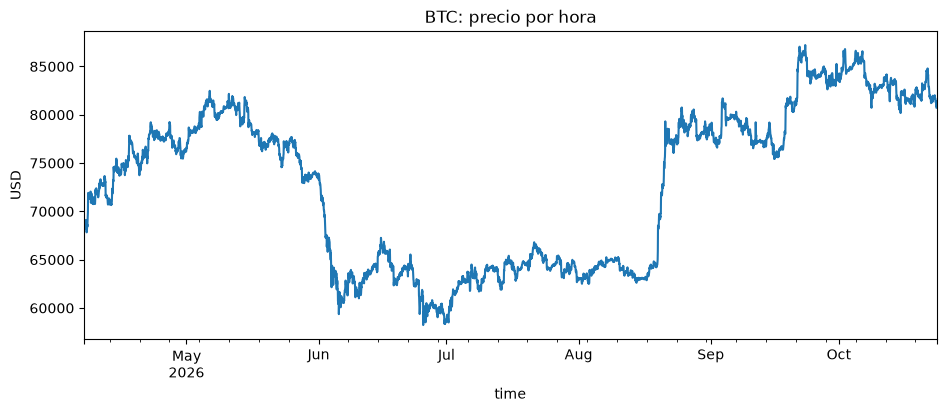

In [5]:
df.plot(x="time", y="close", title=f"{COIN}: precio por hora", legend=False)
plt.ylabel("USD"); plt.show()

## 6. Graficar el funding
Multiplicamos por 100 para verlo en %. Fijate si suele ser positivo, si tiene picos y cuándo.

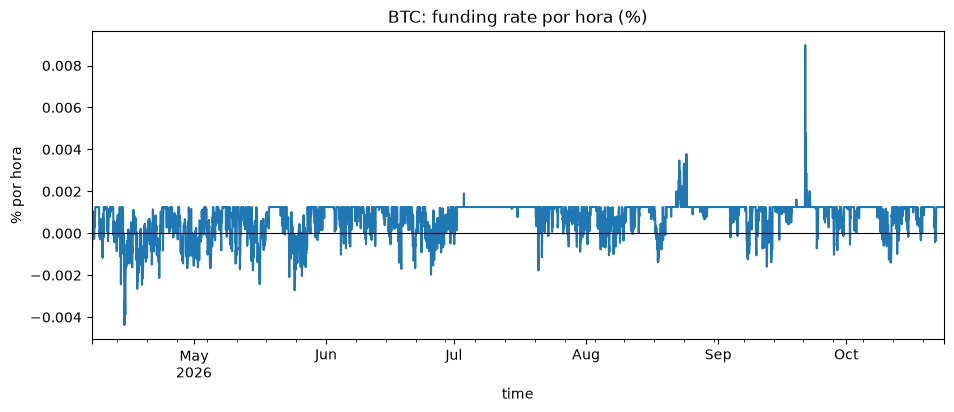

Horas con funding positivo: 84%


In [6]:
(df.set_index("time")["fundingRate"] * 100).plot(title=f"{COIN}: funding rate por hora (%)")
plt.axhline(0, color="black", lw=0.8); plt.ylabel("% por hora"); plt.show()

print(f"Horas con funding positivo: {(df.fundingRate > 0).mean():.0%}")

## Qué anotar antes de seguir
- ¿Hay huecos? ¿Cuántos?
- ¿Algún valor raro? ¿Fue un evento real (buscá la fecha en X o en noticias)?
- ¿El funding suele ser positivo o negativo? ¿Tiene picos?

Estas respuestas van en la sección **Datos** del README.